# Graphs in PyTorch Geometric (lecture notes)

**Week 12 · Graphs and message passing**

A graph consists of *nodes* (here: atoms) and *edges* (here: bonds or
neighbour relations). In PyTorch Geometric a graph is a `Data` object with

* `x` – node attributes, shape `(num_nodes, num_features)`
* `edge_index` – edges as a `(2, num_edges)` tensor; column `[i, j]` is an
  edge from node `i` to node `j`
* optionally `pos` (positions) and `y` (a target property such as the energy).

This notebook walks through the basic operations used in exercises 59–63.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn.aggr import SumAggregation
from torch_geometric.utils import to_dense_adj

from comphy.graphs import NeighbourAggregation, plot_graph

## A three-node chain: 0 – 1 – 2
Every bond appears twice, once in each direction.

In [2]:
x = torch.tensor([[-1.0], [0.0], [1.0]])
edge_index = torch.tensor([[0, 1, 1, 2],
                           [1, 0, 2, 1]])
pos = torch.tensor([[0.0, 0.0], [1.0, 0.5], [2.0, 0.0]])
graph = Data(x=x, edge_index=edge_index, pos=pos, y=42)
print(graph)

for key, item in graph:
    print(f"{key}: {item.tolist() if torch.is_tensor(item) else item}")

Data(x=[3, 1], edge_index=[2, 4], y=42, pos=[3, 2])
x: [[-1.0], [0.0], [1.0]]
edge_index: [[0, 1, 1, 2], [1, 0, 2, 1]]
y: 42
pos: [[0.0, 0.0], [1.0, 0.5], [2.0, 0.0]]


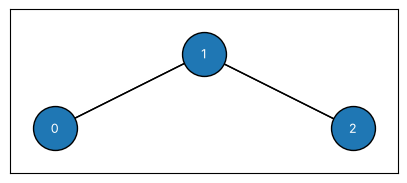

In [3]:
fig, ax = plt.subplots(figsize=(5, 3))
plot_graph(ax, graph, size=1000)
plt.show()

## Adjacency matrix
Row *i* has a 1 in column *j* if node *i* is connected to node *j*. Its
eigenvalues do not depend on how the nodes are numbered, which makes them
useful for comparing graphs (exercise 59).

In [4]:
adjacency = to_dense_adj(graph.edge_index)[0]
print(adjacency)
print("eigenvalues:", np.linalg.eigvalsh(adjacency.numpy()).round(3))

tensor([[0., 1., 0.],
        [1., 0., 1.],
        [0., 1., 0.]])
eigenvalues: [-1.414 -0.     1.414]


## Batching graphs
A `DataLoader` glues several graphs into one big disconnected graph. The
`batch` vector records which graph each node belongs to, and `ptr` where each
graph starts.

In [5]:
loader = DataLoader([graph, graph, graph], batch_size=2)
batch = next(iter(loader))
print(batch)
print("x:      ", batch.x.flatten().tolist())
print("edges:  ", batch.edge_index.tolist())
print("batch:  ", batch.batch.tolist())
print("ptr:    ", batch.ptr.tolist())
print(to_dense_adj(batch.edge_index)[0])

DataBatch(x=[6, 1], edge_index=[2, 8], y=[2], pos=[6, 2], batch=[6], ptr=[3])
x:       [-1.0, 0.0, 1.0, -1.0, 0.0, 1.0]
edges:   [[0, 1, 1, 2, 3, 4, 4, 5], [1, 0, 2, 1, 4, 3, 5, 4]]
batch:   [0, 0, 0, 1, 1, 1]
ptr:     [0, 3, 6]
tensor([[0., 1., 0., 0., 0., 0.],
        [1., 0., 1., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1., 0.],
        [0., 0., 0., 1., 0., 1.],
        [0., 0., 0., 0., 1., 0.]])


## Message passing
In a message-passing step every node collects the attributes of its
neighbours and combines them with an aggregation function.

In [6]:
graph.x = torch.tensor([[5.0], [20.0], [100.0]])
for aggr in ["add", "mul", "min", "max", "mean"]:
    out = NeighbourAggregation(aggr=aggr)(graph.x, graph.edge_index)
    print(f"{aggr:>4}: {out.flatten().tolist()}")

 add: [20.0, 105.0, 20.0]
 mul: [20.0, 500.0, 20.0]
 min: [20.0, 5.0, 20.0]
 max: [20.0, 100.0, 20.0]
mean: [20.0, 52.5, 20.0]


Node 1 has neighbours 0 and 2 (5 and 100); nodes 0 and 2 only see node 1 (20).

## Aggregating a whole graph
A *global* aggregation reduces all node attributes of each graph in a batch
to one number – e.g. the total energy as a sum of atomic energies.

In [7]:
print(SumAggregation()(graph.x, torch.zeros(3, dtype=torch.long)))

tensor([[125.]])
